# Brick 10 - SHAP explanations

**Gate:** Per-class SHAP summary plots and the 18-feature meaning table.

The narrative report for this brick is `reports/brick10_shap_S.md`. The cells below load the saved artifacts; they do not retrain anything.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown
import pandas as pd

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
FIGURES = ROOT / "figures"

def md(name):
    p = REPORTS / name
    display(Markdown(p.read_text(encoding="utf-8"))) if p.exists() else print("missing", name)

def js(name, keys=None, indent=2):
    p = REPORTS / name
    if not p.exists():
        print("missing", name); return None
    d = json.loads(p.read_text(encoding="utf-8"))
    print(json.dumps({k: d[k] for k in keys} if keys else d, indent=indent)[:6000])
    return d


# Brick 10 - SHAP (Mode S)

Backend: TreeExplainer; sample: 5,000 test pairs.

## Overall top 10 (mean |SHAP| across classes)

| feature               |   mean_abs_shap |
|:----------------------|----------------:|
| EstateVSA1*MTPSA      |        0.154809 |
| EstateVSA4*PEOEVSA8   |        0.151437 |
| PEOEVSA8+PEOEVSA8     |        0.13857  |
| PEOEVSA13+PEOEVSA13   |        0.128625 |
| PEOEVSA7+PEOEVSA7     |        0.124842 |
| EstateVSA7+EstateVSA7 |        0.124767 |
| VSAEstate7+VSAEstate7 |        0.12144  |
| VSAEstate7*PEOEVSA13  |        0.120442 |
| slogPVSA10+slogPVSA10 |        0.113696 |
| PEOEVSA3+PEOEVSA3     |        0.104011 |

## Paper's top features

Paper list: MRVSA0, PEOEVSA5, EstateVSA7, PEOEVSA9, EstateVSA2. Present in our top 10: EstateVSA7+EstateVSA7.

## Per-class top 5

| negative             | positive              | non_significant       |
|:---------------------|:----------------------|:----------------------|
| EstateVSA4*PEOEVSA8  | PEOEVSA7+PEOEVSA7     | EstateVSA1*MTPSA      |
| PEOEVSA8+PEOEVSA8    | EstateVSA7+EstateVSA7 | MRVSA6*VSAEstate0     |
| PEOEVSA13+PEOEVSA13  | EstateVSA4*PEOEVSA8   | VSAEstate7+VSAEstate7 |
| VSAEstate7*PEOEVSA13 | PEOEVSA8+PEOEVSA8     | EstateVSA2+EstateVSA2 |
| PEOEVSA3+PEOEVSA3    | slogPVSA10+slogPVSA10 | VSAEstate8+VSAEstate8 |

## Feature definitions

| name                       | term     | drug_descriptor_meaning                                           | food_descriptor_meaning                                           |
|:---------------------------|:---------|:------------------------------------------------------------------|:------------------------------------------------------------------|
| EstateVSA8*EstateVSA6      | product  | surface-area contribution to electrotopological state             | surface-area contribution to electrotopological state             |
| slogPVSA10+slogPVSA10      | sum      | van der Waals surface-area contribution to SlogP (hydrophobicity) | van der Waals surface-area contribution to SlogP (hydrophobicity) |
| PEOEVSA3+PEOEVSA3          | sum      | surface-area contribution to Gasteiger partial charge             | surface-area contribution to Gasteiger partial charge             |
| PEOEVSA7+PEOEVSA7          | sum      | surface-area contribution to Gasteiger partial charge             | surface-area contribution to Gasteiger partial charge             |
| PEOEVSA8+PEOEVSA8          | sum      | surface-area contribution to Gasteiger partial charge             | surface-area contribution to Gasteiger partial charge             |
| PEOEVSA13+PEOEVSA13        | sum      | surface-area contribution to Gasteiger partial charge             | surface-area contribution to Gasteiger partial charge             |
| EstateVSA2+EstateVSA2      | sum      | surface-area contribution to electrotopological state             | surface-area contribution to electrotopological state             |
| EstateVSA7+EstateVSA7      | sum      | surface-area contribution to electrotopological state             | surface-area contribution to electrotopological state             |
| VSAEstate6+VSAEstate6      | sum      | VSA-binned electrotopological state contribution                  | VSA-binned electrotopological state contribution                  |
| VSAEstate7+VSAEstate7      | sum      | VSA-binned electrotopological state contribution                  | VSA-binned electrotopological state contribution                  |
| VSAEstate8+VSAEstate8      | sum      | VSA-binned electrotopological state contribution                  | VSA-binned electrotopological state contribution                  |
| abs(VSAEstate7-VSAEstate7) | abs_diff | VSA-binned electrotopological state contribution                  | VSA-binned electrotopological state contribution                  |
| slogPVSA3*EstateVSA1       | product  | van der Waals surface-area contribution to SlogP (hydrophobicity) | surface-area contribution to electrotopological state             |
| MRVSA6*VSAEstate0          | product  | surface-area contribution to molar refractivity                   | VSA-binned electrotopological state contribution                  |
| EstateVSA1*MTPSA           | product  | surface-area contribution to electrotopological state             | topological polar surface area (MOE TPSA)                         |
| EstateVSA4*PEOEVSA8        | product  | surface-area contribution to electrotopological state             | surface-area contribution to Gasteiger partial charge             |
| VSAEstate2*VSAEstate1      | product  | VSA-binned electrotopological state contribution                  | VSA-binned electrotopological state contribution                  |
| VSAEstate7*PEOEVSA13       | product  | VSA-binned electrotopological state contribution                  | surface-area contribution to Gasteiger partial charge             |

Chemical readings of these features are hypotheses, not confirmed mechanisms.

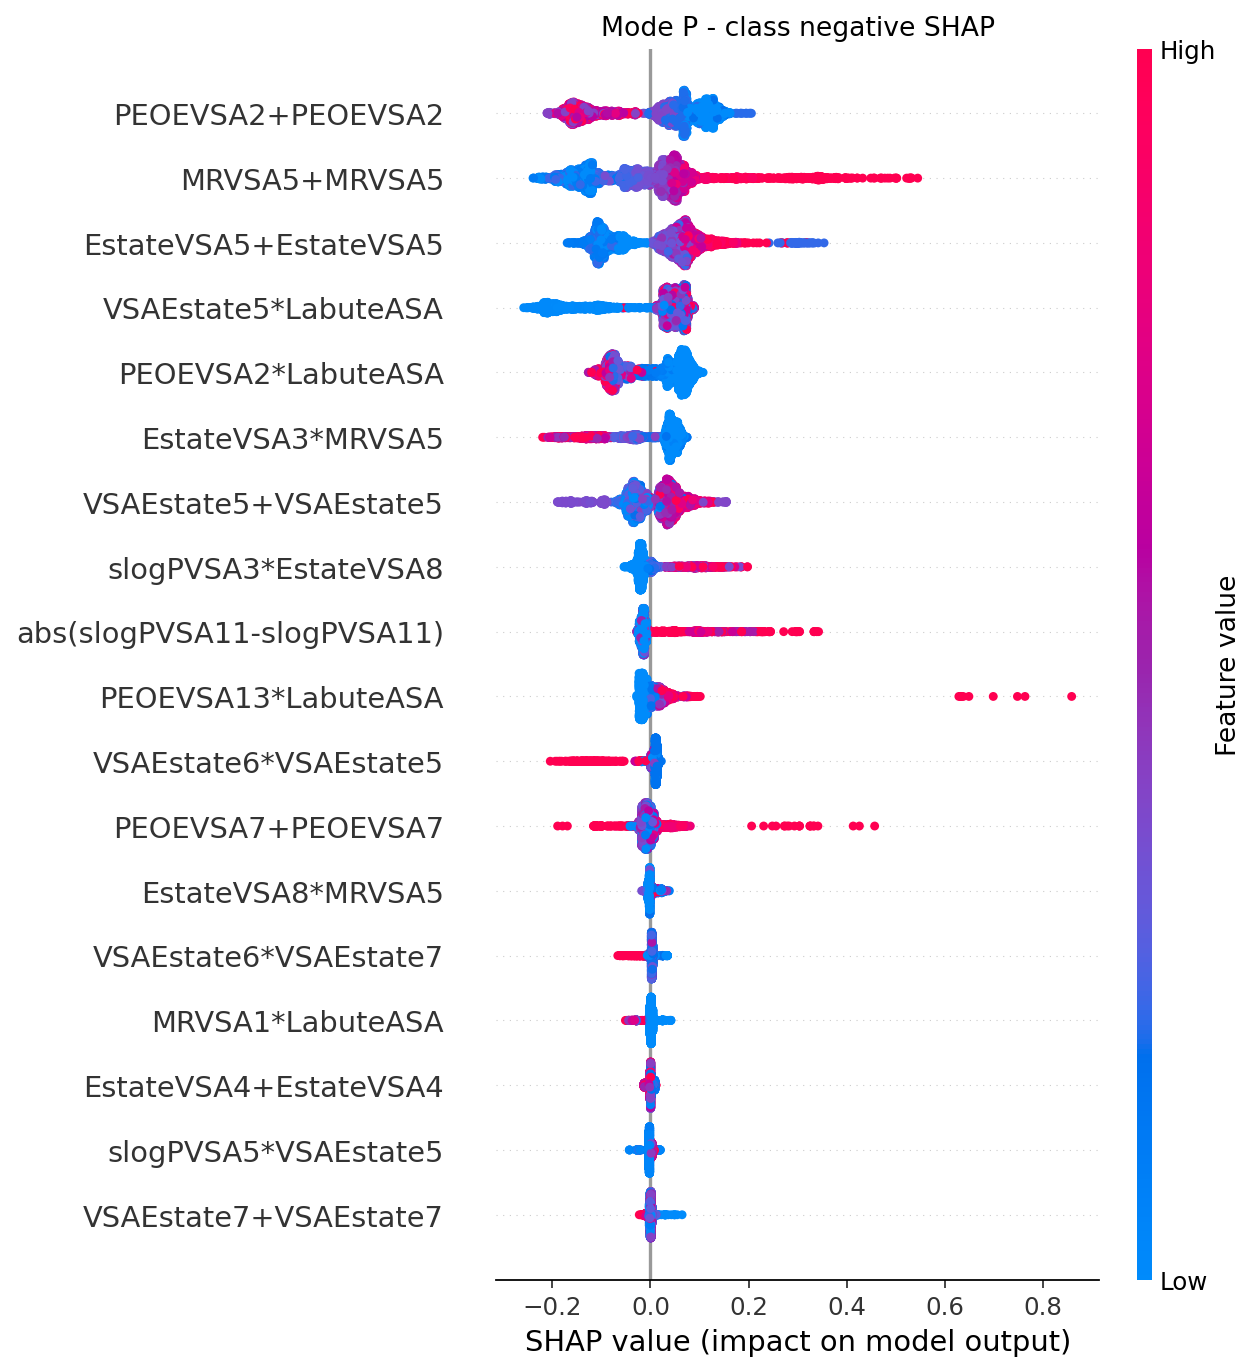

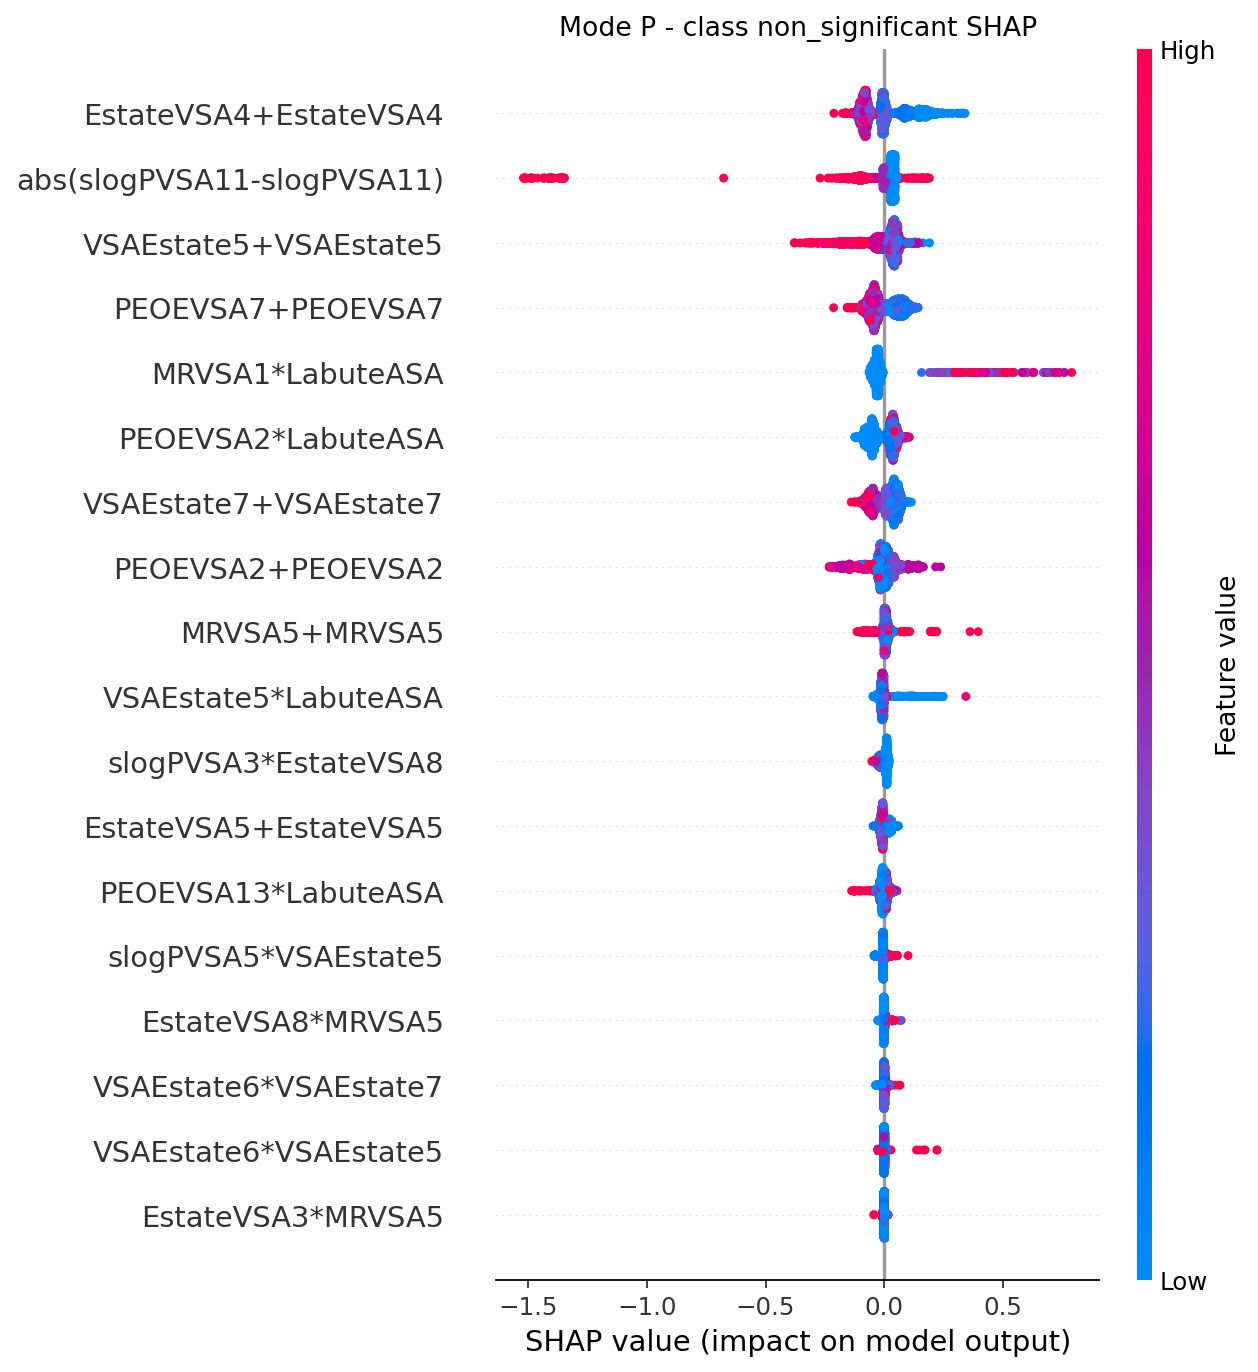

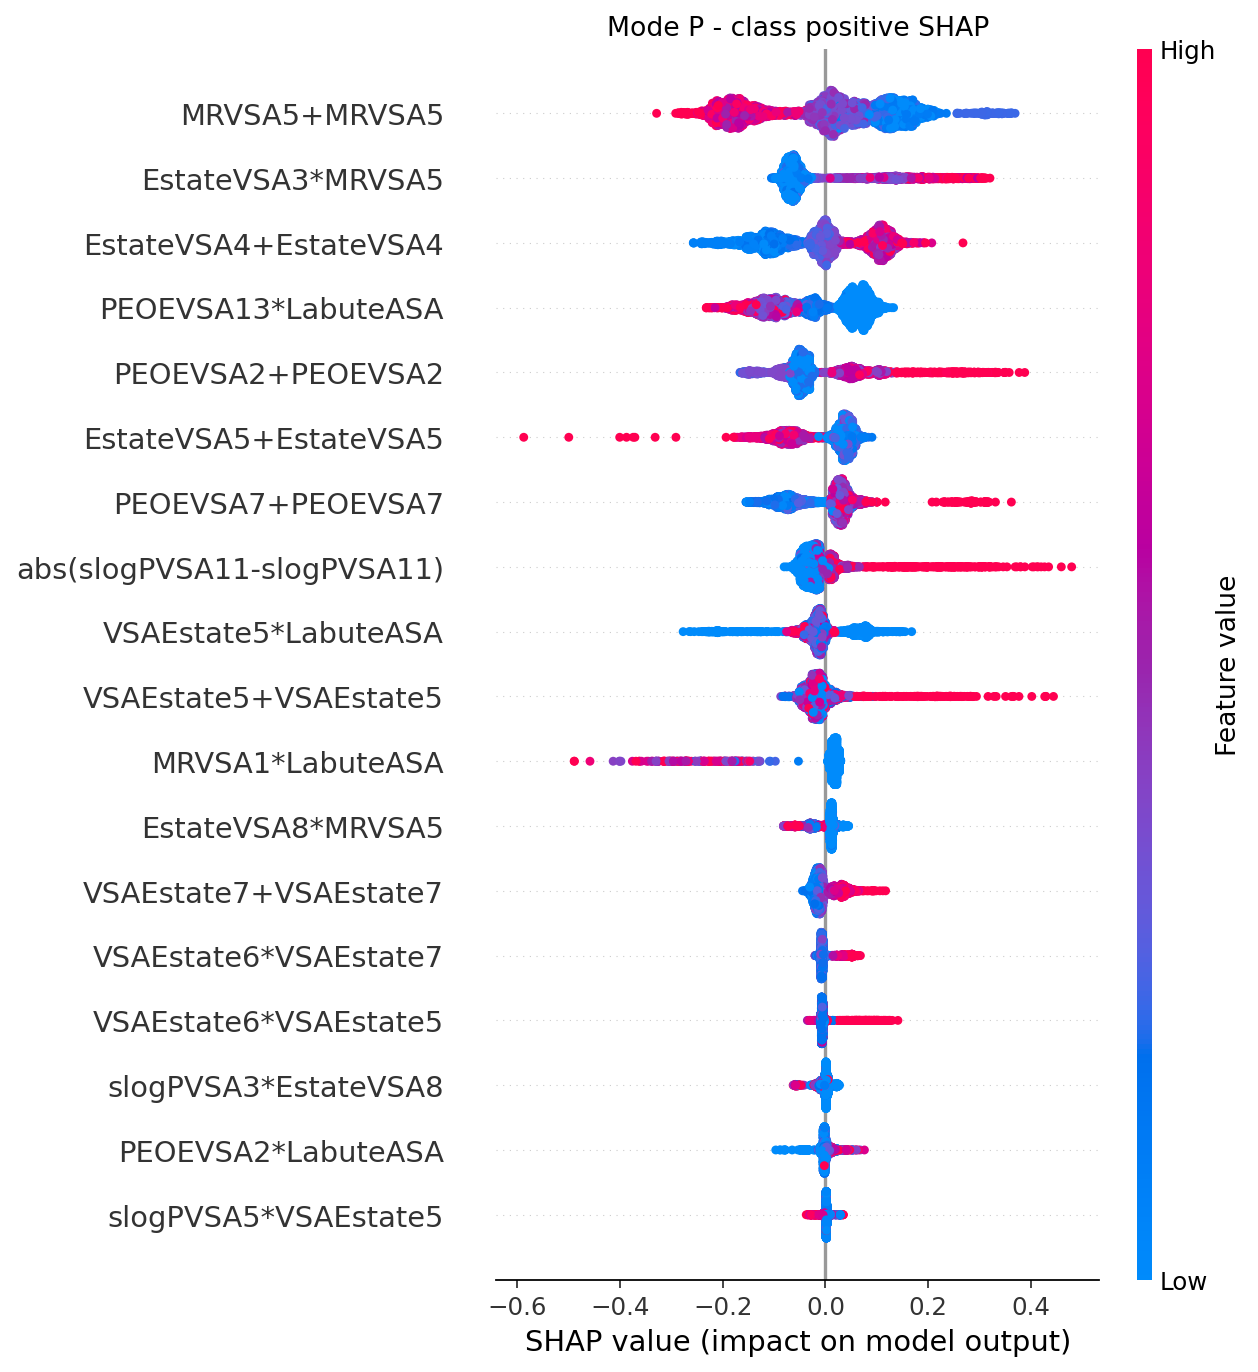

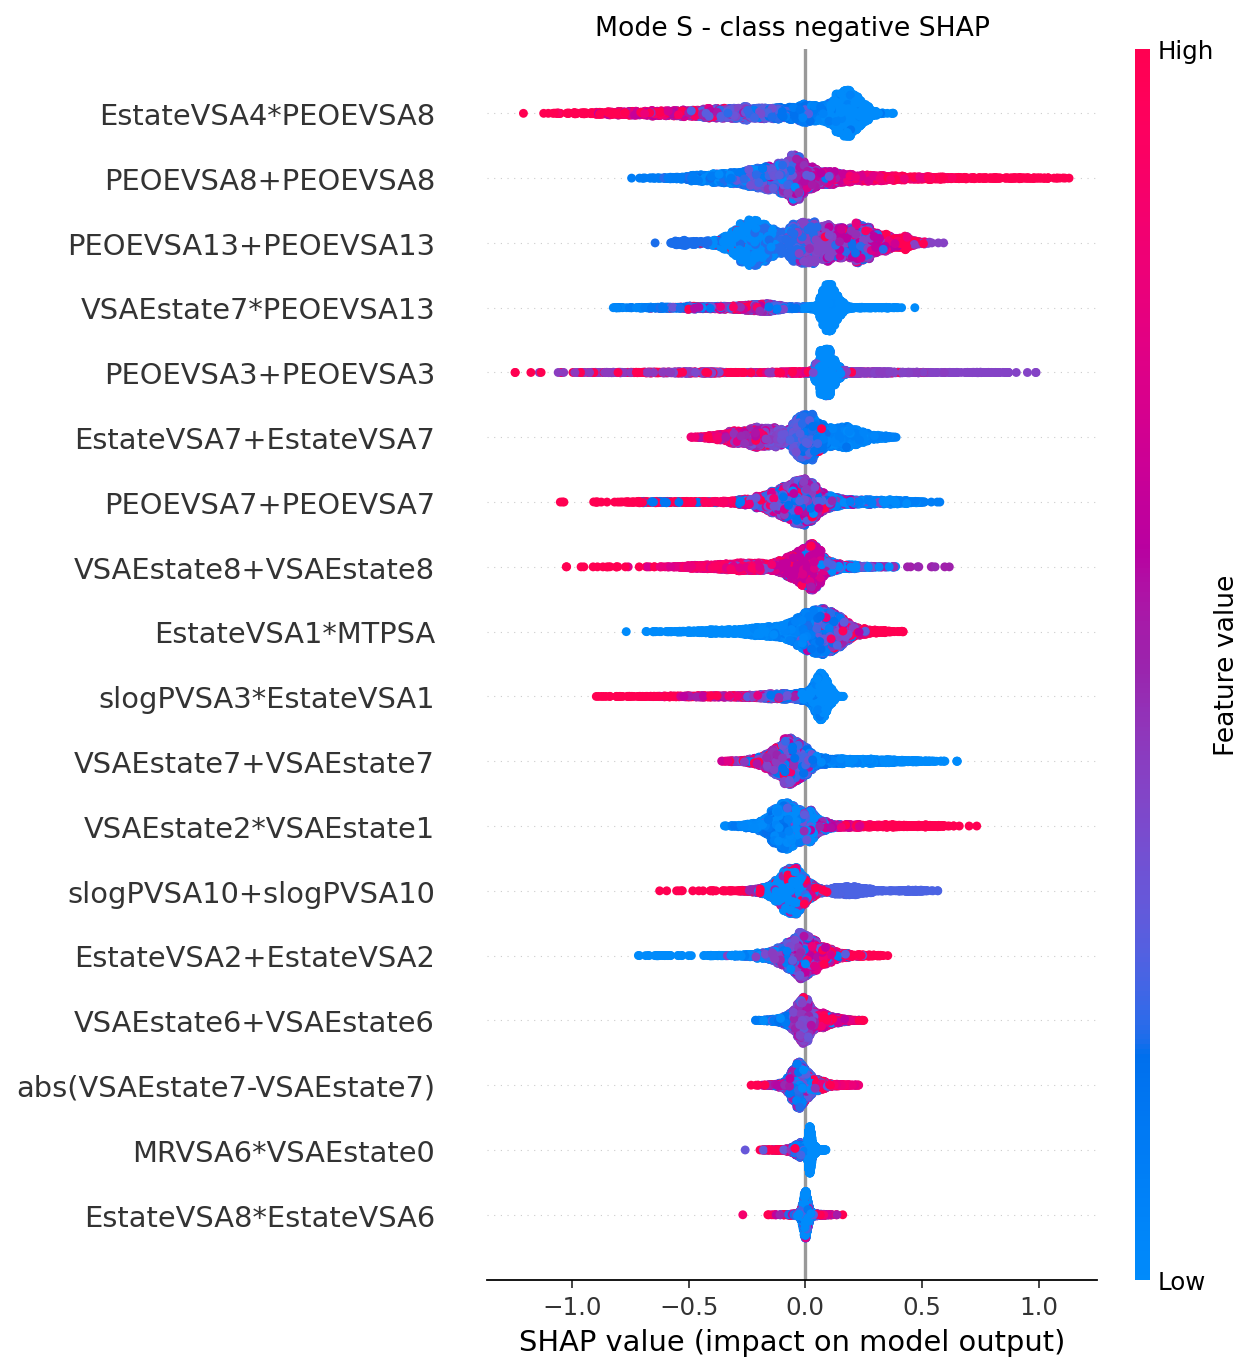

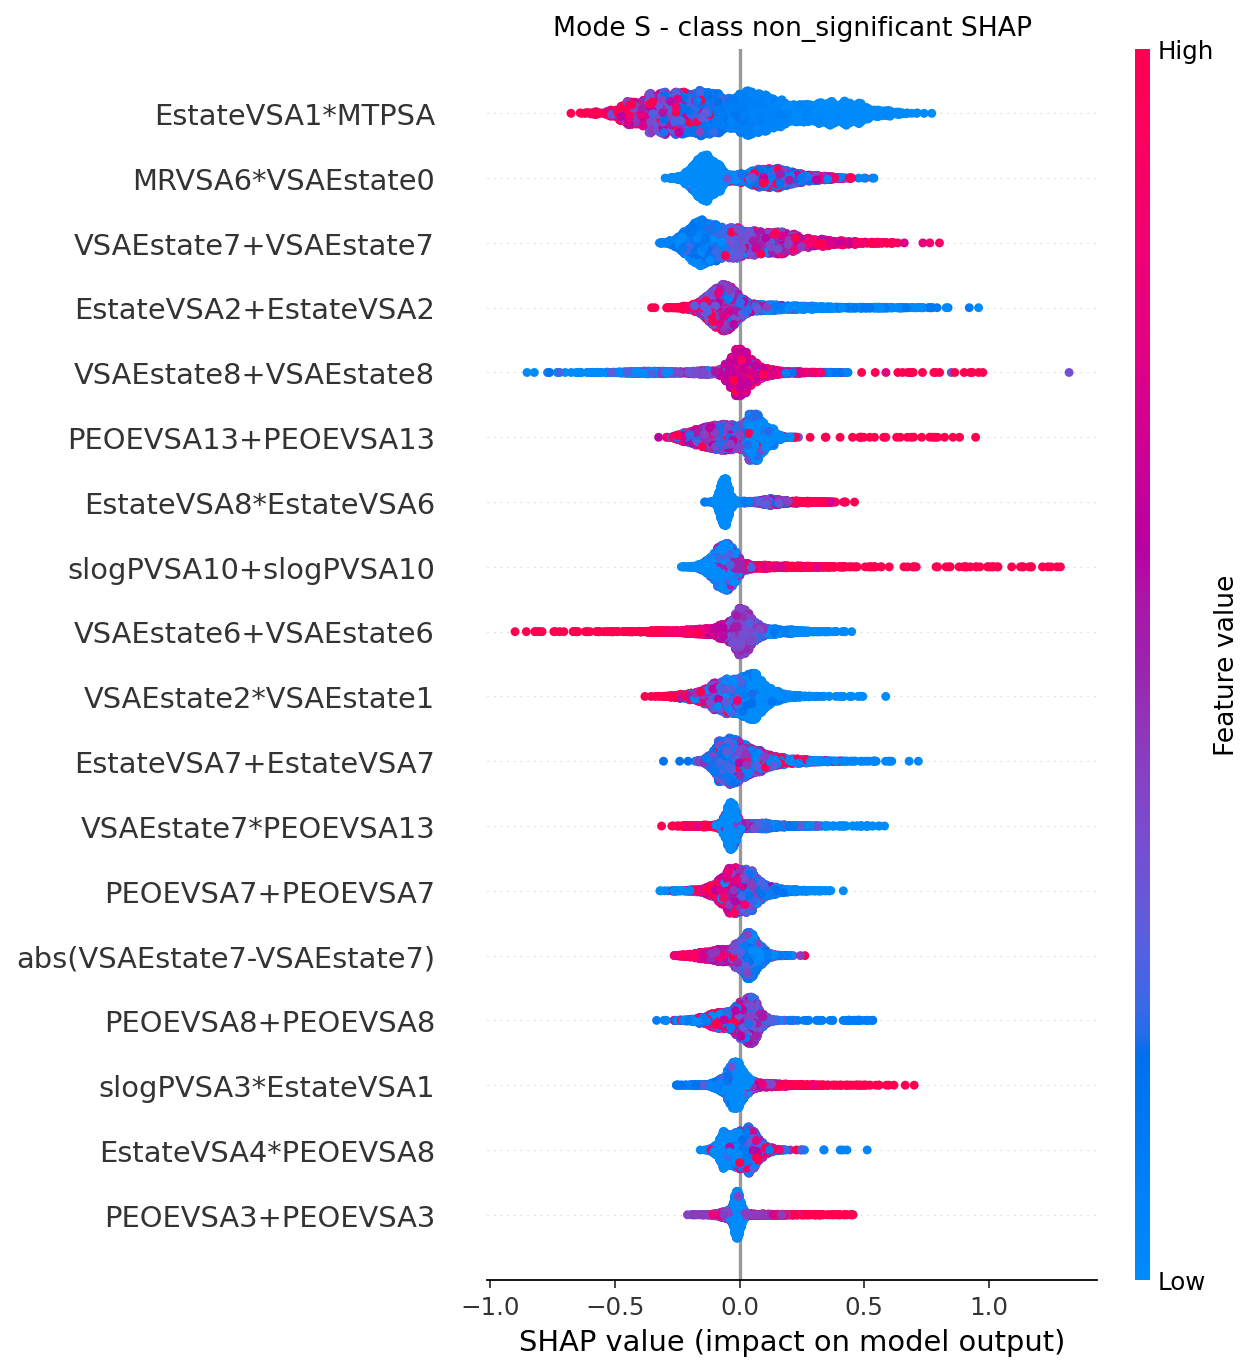

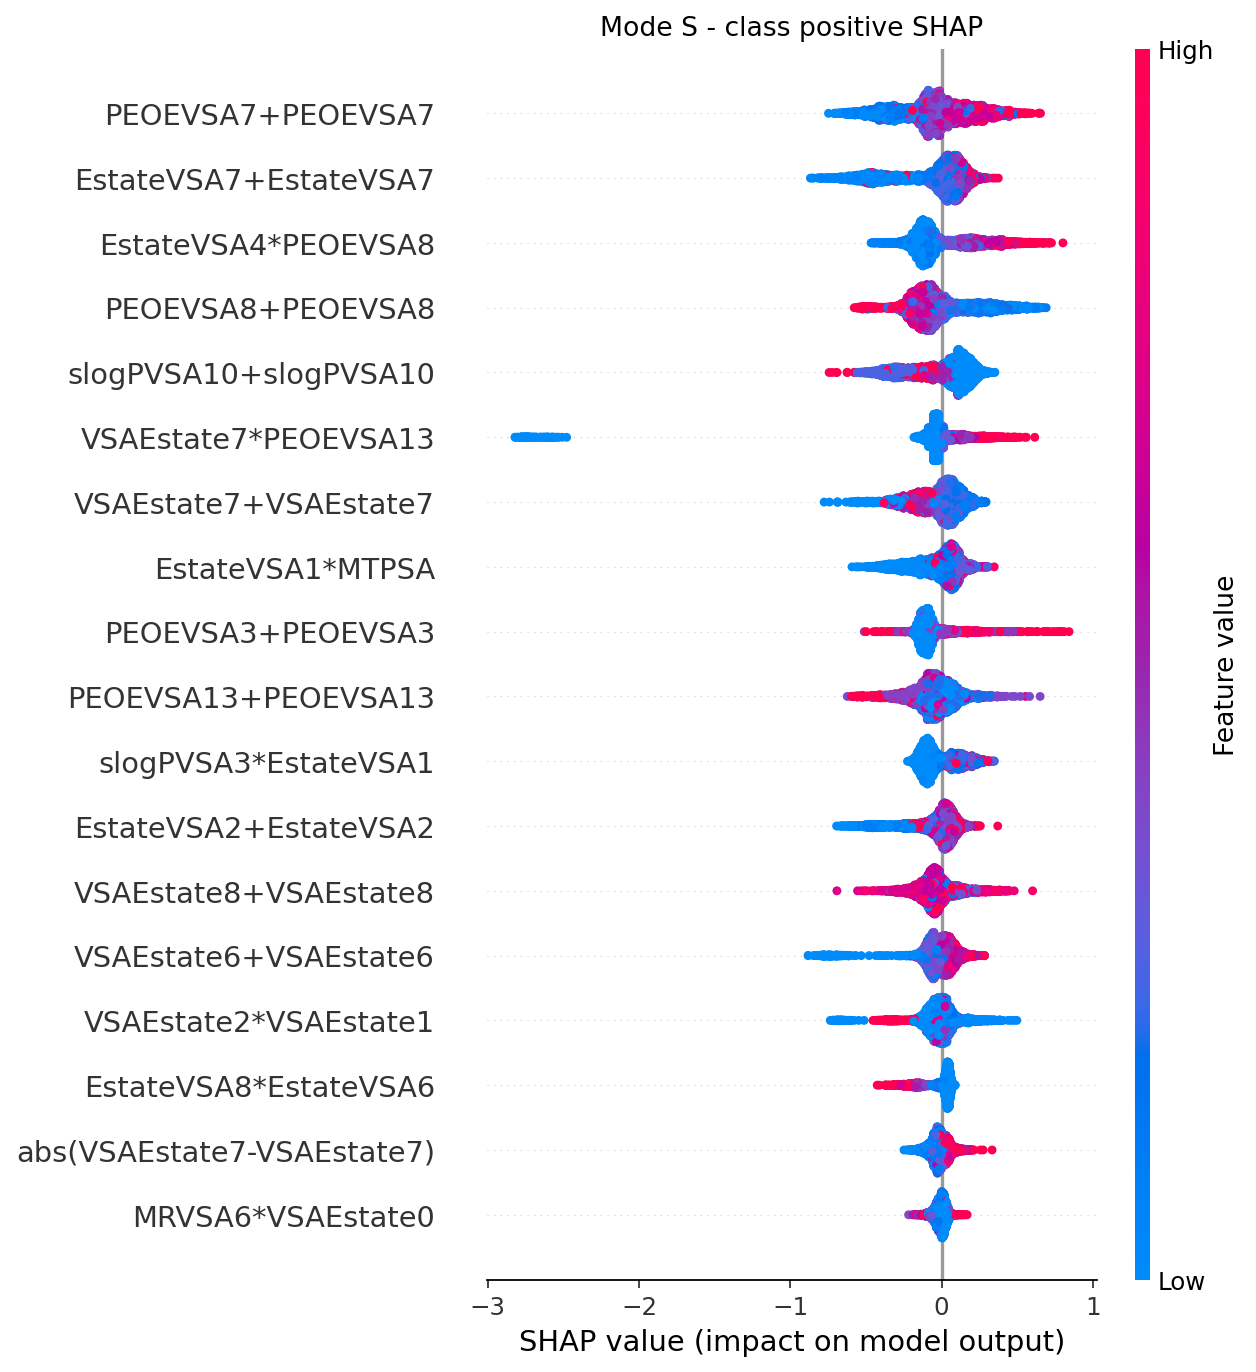

In [2]:
md('brick10_shap_S.md')
for f in sorted(FIGURES.glob('shap_*.png')): display(Image(filename=str(f)))

In [3]:
# Reproduce this brick from scratch (long running):
# !cd .. && PYTHONPATH=src python src/brick10_*.py